# Championship 25/26 GK Ratings

## Libraries

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

## Functions

In [98]:
def vif_func(df):
  x = add_constant(df)
  vif_data = pd.DataFrame()
  vif_data['feature'] = x.columns
  vif_data['VIF'] = [variance_inflation_factor(x.values, i) for i in range (len(x.columns))]
  vif_data.sort_values('VIF', ascending=False)
  return vif_data

## Data Prepraration

In [99]:
all_data = pd.read_excel('/content/drive/MyDrive/Football Data Analysis/Models/EFL Ch 2526 Player Data.xlsx', index_col=0)

In [100]:
all_data1500 = all_data[all_data['minutesPlayed'] >= 1500]

In [101]:
gk_data = pd.read_excel('/content/drive/MyDrive/Football Data Analysis/Models/EFL Ch 2526 Goalkeeper Data (Per 90).xlsx')

In [102]:
gk_data['accurateOppositionHalfPassesPercentage'] = (gk_data['accurateOppositionHalfPasses'] / gk_data['totalOppositionHalfPasses']) * 100
gk_data['accurateOwnHalfPassesPercentage'] = (gk_data['accurateOwnHalfPasses'] / gk_data['totalOwnHalfPasses']) * 100

In [103]:
player_id1500 = all_data1500['player id'].tolist()

In [104]:
gk_data1500 = gk_data[gk_data['player id'].isin(player_id1500)].copy()

In [105]:
gk_data1500.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
Index: 27 entries, 3 to 44
Data columns (total 116 columns):
 #    Column                                  Non-Null Count  Dtype  
---   ------                                  --------------  -----  
 0    accurateChippedPasses                   27 non-null     float64
 1    accurateCrosses                         27 non-null     int64  
 2    accurateCrossesPercentage               27 non-null     int64  
 3    accurateFinalThirdPasses                27 non-null     float64
 4    accurateLongBalls                       27 non-null     float64
 5    accurateLongBallsPercentage             27 non-null     float64
 6    accurateOppositionHalfPasses            27 non-null     float64
 7    accurateOwnHalfPasses                   27 non-null     float64
 8    accuratePasses                          27 non-null     float64
 9    accuratePassesPercentage                27 non-null     float64
 10   aerialDuelsWon                          27 non-null    

In [106]:
gk_data1500.iloc[:,[6,100,114,7,101,115]].head()

,accurateOppositionHalfPasses,totalOppositionHalfPasses,accurateOppositionHalfPassesPercentage,accurateOwnHalfPasses,totalOwnHalfPasses,accurateOwnHalfPassesPercentage
3,3.04,11.91,25.524769,19.43,22.16,87.680505
4,4.00,13.08,30.581040,22.04,23.80,92.605042
6,3.82,13.02,29.339478,18.40,20.56,89.494163
7,5.09,17.46,29.152348,19.96,21.57,92.535930
8,6.50,19.97,32.548823,10.75,11.97,89.807853


## Passing Data

In [107]:
passing_cols = [3,5,8,9]

In [108]:
passing_data = gk_data1500.iloc[:,passing_cols]

In [109]:
passing_data.head()

,accurateFinalThirdPasses,accurateLongBallsPercentage,accuratePasses,accuratePassesPercentage
3,1.12,27.09,22.48,65.97
4,1.32,41.36,26.04,70.61
6,1.11,34.55,22.22,66.18
7,2.02,32.59,25.04,64.18
8,2.84,34.86,17.25,54.01


In [110]:
x = add_constant(passing_data)
vif_data = pd.DataFrame()
vif_data['feature'] = x.columns
vif_data['VIF'] = [variance_inflation_factor(x.values, i) for i in range (len(x.columns))]
vif_data.sort_values('VIF', ascending=False)

,feature,VIF
0,const,112.581164
4,accuratePassesPercentage,4.202782
3,accuratePasses,2.747786
1,accurateFinalThirdPasses,1.992096
2,accurateLongBallsPercentage,1.366285


In [111]:
passing_data.corr()

,accurateFinalThirdPasses,accurateLongBallsPercentage,accuratePasses,accuratePassesPercentage
accurateFinalThirdPasses,1.000000,0.034581,0.028874,-0.458445
accurateLongBallsPercentage,0.034581,1.000000,0.284804,0.418967
accuratePasses,0.028874,0.284804,1.000000,0.687422
accuratePassesPercentage,-0.458445,0.418967,0.687422,1.000000


In [112]:
scaler = StandardScaler()

scaled_passing_data = pd.DataFrame(scaler.fit_transform(passing_data),
                                   columns=passing_data.columns,
                                   index=passing_data.index)

In [113]:
scaled_passing_data.head()

,accurateFinalThirdPasses,accurateLongBallsPercentage,accuratePasses,accuratePassesPercentage
3,-0.604406,-0.995453,0.813996,0.824508
4,-0.372107,2.300398,1.673696,1.393371
6,-0.616021,0.727535,0.751209,0.850254
7,0.440937,0.274847,1.432207,0.605054
8,1.393360,0.799134,-0.448990,-0.641788


In [114]:
passing_rating_data = np.where(scaled_passing_data >= 0,
                               100 / (1 + np.exp(-0.9 * scaled_passing_data)),
                               100 / (1 + np.exp(-0.3 * scaled_passing_data)))

passing_rating_data = pd.DataFrame(passing_rating_data,
                                   columns=scaled_passing_data.columns,
                                   index=scaled_passing_data.index)

In [115]:
passing_rating_data.describe()

,accurateFinalThirdPasses,accurateLongBallsPercentage,accuratePasses,accuratePassesPercentage
count,27.000000,27.000000,27.000000,27.000000
mean,54.007329,55.245173,55.129746,55.301936
std,13.547013,13.791144,14.587169,14.592399
min,39.943674,31.011191,36.809499,33.760476
25%,45.436142,44.847681,45.773353,44.610012
50%,47.472685,48.354978,48.715697,47.964604
75%,58.268297,65.597634,66.911987,67.025223
max,95.791980,88.798859,83.198794,85.423599


In [116]:
passing_rating_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 27 entries, 3 to 44
Data columns (total 4 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   accurateFinalThirdPasses     27 non-null     float64
 1   accurateLongBallsPercentage  27 non-null     float64
 2   accuratePasses               27 non-null     float64
 3   accuratePassesPercentage     27 non-null     float64
dtypes: float64(4)
memory usage: 1.1 KB


In [117]:
w1 = 0.4
w2 = 0.1
passing_weights = pd.Series([w2,w1,w2,w1],
                            index=passing_data.columns)

In [118]:
passing_rating_data['passing_overall_rating'] = passing_rating_data @ passing_weights

In [119]:
passing_rating_data['player'] = gk_data1500['player']
passing_rating_data = passing_rating_data.sort_values('passing_overall_rating', ascending=False)

In [120]:
passing_rating_data

,accurateFinalThirdPasses,accurateLongBallsPercentage,accuratePasses,accuratePassesPercentage,passing_overall_rating,player
4,47.212088,88.798859,81.851609,77.799743,79.545811,Viktor Johansson
37,43.757462,66.599348,79.267863,83.726498,72.432871,Gavin Bazunu
25,42.220412,65.386542,70.825159,85.423599,71.628614,Christian Walton
19,39.943674,64.677513,58.716346,79.431487,67.509602,Vladan Kovačević
6,45.392949,65.808725,66.286500,68.248775,64.790945,Lawrence Vigouroux
16,72.961855,80.949872,48.136705,47.093235,63.327099,Thomas Kaminski
22,44.100771,67.608774,49.602894,66.305901,62.936237,Egil Selvik
7,59.792891,56.152711,78.397555,63.286981,61.594922,Carl Rushworth
8,77.799561,67.243541,46.637656,45.201403,57.421699,Jacob Widell Zetterström
44,61.291062,64.296682,46.781922,51.062373,56.950921,Paul Nardi


[]

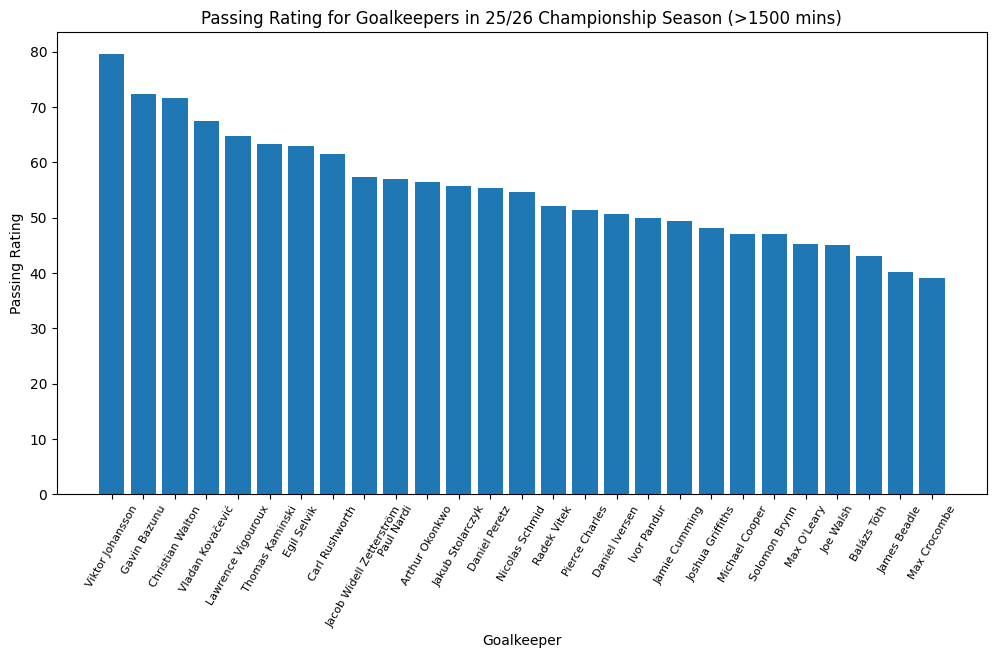

In [121]:
plt.figure(figsize=(12,6))
plt.bar(passing_rating_data['player'], passing_rating_data['passing_overall_rating'])
plt.xticks(rotation=60, size=8)
plt.xlabel('Goalkeeper')
plt.ylabel('Passing Rating')
plt.title('Passing Rating for Goalkeepers in 25/26 Championship Season (>1500 mins)')
plt.plot()

## Saving Data

In [122]:
gk_data1500['penaltySavePercentage'] = np.where(gk_data1500['penaltyFaced'] > 0,
                                               (gk_data1500['penaltySave'] / gk_data1500['penaltyFaced']) * 100,
                                                0)

gk_data1500['savePercentage'] = (gk_data1500['saves'] / (gk_data1500['saves'] + gk_data1500['goalsConceded'])) * 100

In [123]:
gk_data1500.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
Index: 27 entries, 3 to 44
Data columns (total 118 columns):
 #    Column                                  Non-Null Count  Dtype  
---   ------                                  --------------  -----  
 0    accurateChippedPasses                   27 non-null     float64
 1    accurateCrosses                         27 non-null     int64  
 2    accurateCrossesPercentage               27 non-null     int64  
 3    accurateFinalThirdPasses                27 non-null     float64
 4    accurateLongBalls                       27 non-null     float64
 5    accurateLongBallsPercentage             27 non-null     float64
 6    accurateOppositionHalfPasses            27 non-null     float64
 7    accurateOwnHalfPasses                   27 non-null     float64
 8    accuratePasses                          27 non-null     float64
 9    accuratePassesPercentage                27 non-null     float64
 10   aerialDuelsWon                          27 non-null    

In [124]:
saving_cols = [66,116,77,117,45]

In [125]:
saving_data = gk_data1500.iloc[:, saving_cols]

In [126]:
saving_data

,penaltySave,penaltySavePercentage,saves,savePercentage,goalsPrevented
3,0.00,0.000000,2.87,77.150538,0.33
4,0.00,0.000000,2.92,74.489796,0.17
6,0.00,0.000000,3.22,71.396896,0.03
7,0.00,0.000000,2.67,73.150685,0.15
8,0.03,18.750000,3.28,71.459695,0.17
9,0.00,0.000000,4.26,68.599034,0.04
12,0.03,37.500000,2.87,70.864198,0.08
13,0.00,0.000000,3.27,71.241830,0.13
14,0.00,0.000000,3.39,75.669643,0.15
16,0.03,21.428571,2.86,68.421053,-0.17


In [127]:
vif_func(saving_data)

,feature,VIF
0,const,1065.718530
1,penaltySave,4.911448
2,penaltySavePercentage,5.106088
3,saves,1.275081
4,savePercentage,4.292186
5,goalsPrevented,4.135858


In [128]:
scaled_saving_data = pd.DataFrame(scaler.fit_transform(saving_data),
                                  columns=saving_data.columns,
                                  index=saving_data.index)

In [129]:
scaled_saving_data.head()

,penaltySave,penaltySavePercentage,saves,savePercentage,goalsPrevented
3,-0.837607,-0.731551,0.129468,1.950853,2.040462
4,-0.837607,-0.731551,0.237359,1.339126,1.053363
6,-0.837607,-0.731551,0.884701,0.628042,0.189651
7,-0.837607,-0.731551,-0.302093,1.031253,0.929975
8,0.817178,-0.057017,1.014170,0.642480,1.053363


In [130]:
saving_rating_data = np.where(scaled_saving_data >= 0,
                               100 / (1 + np.exp(-0.9 * scaled_saving_data)),
                               100 / (1 + np.exp(-0.3 * scaled_saving_data)))

saving_rating_data = pd.DataFrame(saving_rating_data,
                                  columns=saving_data.columns,
                                  index=saving_data.index)

In [131]:
saving_rating_data.describe()

,penaltySave,penaltySavePercentage,saves,savePercentage,goalsPrevented
count,27.000000,27.000000,27.000000,27.000000,27.000000
mean,55.848187,54.774597,54.202283,54.764916,55.450873
std,14.858983,14.944022,13.116803,13.485358,13.211385
min,43.750793,44.535280,35.387975,34.891110,34.798577
25%,43.750793,44.535280,47.171264,47.586850,44.965543
50%,43.750793,44.535280,52.425629,49.945421,54.256818
75%,67.600230,63.547228,56.993534,63.394075,66.148232
max,90.245163,92.952198,94.353111,85.267884,86.252426


In [132]:
sw1 = 0.05
sw2 = 0.1
sw3 = 0.35
sw4 = 0.45

saving_weights = pd.Series([sw1,sw1,sw2,sw3,sw4],
                           index=saving_rating_data.columns)

saving_rating_data['saving_overall_rating'] = saving_rating_data @ saving_weights

In [133]:
saving_rating_data['player'] = gk_data1500['player']
saving_rating_data = saving_rating_data.sort_values('saving_overall_rating', ascending=False)
saving_rating_data

,penaltySave,penaltySavePercentage,saves,savePercentage,goalsPrevented,saving_overall_rating,player
3,43.750793,44.535280,52.909749,85.267884,86.252426,78.362630,Daniel Peretz
14,43.750793,44.535280,75.516945,80.989755,69.782834,71.714688,Max Crocombe
4,43.750793,44.535280,55.320358,76.945093,72.071813,69.309438,Viktor Johansson
8,67.600230,49.572383,71.356314,64.066048,72.071813,67.849694,Jacob Widell Zetterström
25,67.600230,63.547228,47.735851,69.098643,69.782834,66.917758,Christian Walton
7,43.750793,44.535280,47.735851,71.669528,69.782834,65.674499,Carl Rushworth
13,43.750793,44.535280,70.957741,63.021793,67.391133,63.893715,Radek Vitek
20,77.415018,65.400938,65.054797,56.180309,64.905332,62.516785,Ivor Pandur
12,67.600230,63.547228,52.909749,61.183045,61.023677,60.723068,Daniel Iversen
6,43.750793,44.535280,68.916772,63.766357,54.256818,58.039774,Lawrence Vigouroux


[]

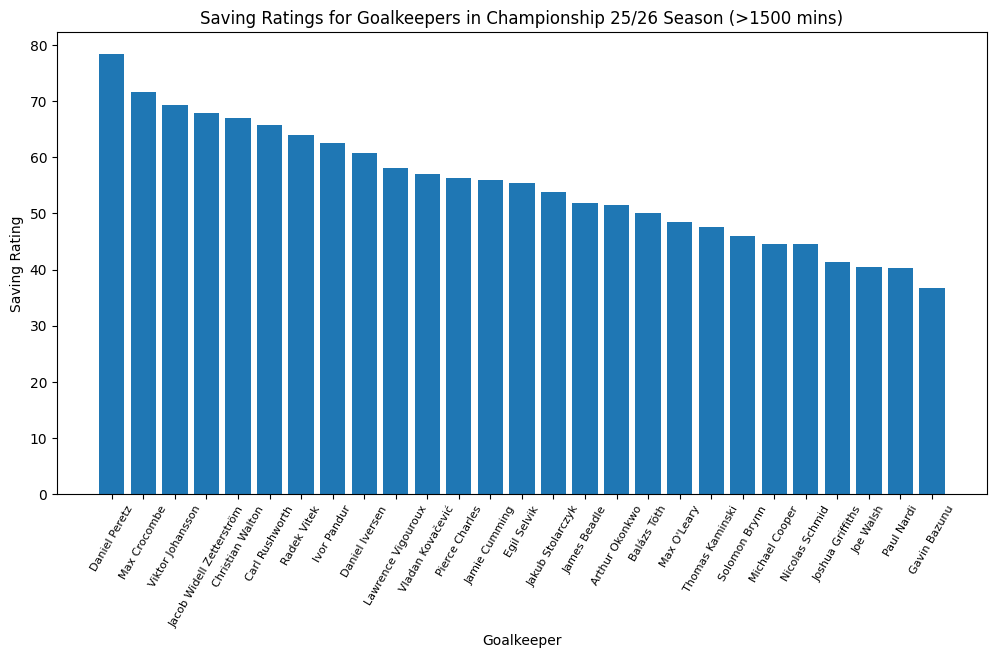

In [134]:
plt.figure(figsize=(12, 6))
plt.bar(saving_rating_data['player'], saving_rating_data['saving_overall_rating'])
plt.xticks(size=8, rotation=60)
plt.xlabel('Goalkeeper')
plt.ylabel('Saving Rating')
plt.title('Saving Ratings for Goalkeepers in Championship 25/26 Season (>1500 mins)')
plt.plot()

## Sweeping Data

In [135]:
gk_data1500['successfulRunsOutPercentage'] = (gk_data1500['successfulRunsOut'] / gk_data1500['runsOut']) * 100

In [136]:
gk_data1500.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
Index: 27 entries, 3 to 44
Data columns (total 119 columns):
 #    Column                                  Non-Null Count  Dtype  
---   ------                                  --------------  -----  
 0    accurateChippedPasses                   27 non-null     float64
 1    accurateCrosses                         27 non-null     int64  
 2    accurateCrossesPercentage               27 non-null     int64  
 3    accurateFinalThirdPasses                27 non-null     float64
 4    accurateLongBalls                       27 non-null     float64
 5    accurateLongBallsPercentage             27 non-null     float64
 6    accurateOppositionHalfPasses            27 non-null     float64
 7    accurateOwnHalfPasses                   27 non-null     float64
 8    accuratePasses                          27 non-null     float64
 9    accuratePassesPercentage                27 non-null     float64
 10   aerialDuelsWon                          27 non-null    

In [137]:
sweeping_cols = [89,18]

In [138]:
sweeping_data = gk_data1500.iloc[:, sweeping_cols]

In [139]:
vif_func(sweeping_data)

,feature,VIF
0,const,99.922007
1,successfulRunsOut,1.309257
2,ballRecovery,1.309257


In [140]:
scaled_sweeping_data = pd.DataFrame(scaler.fit_transform(sweeping_data),
                                    columns=sweeping_data.columns,
                                    index=sweeping_data.index)

In [141]:
sweeping_rating_data = np.where(scaled_sweeping_data >= 0,
                               100 / (1 + np.exp(-0.9 * scaled_sweeping_data)),
                               100 / (1 + np.exp(-0.3 * scaled_sweeping_data)))

sweeping_rating_data = pd.DataFrame(sweeping_rating_data,
                                    columns=sweeping_data.columns,
                                    index=sweeping_data.index)

In [142]:
sweeping_rating_data.describe()

,successfulRunsOut,ballRecovery
count,27.000000,27.000000
mean,54.087577,54.973891
std,14.091025,14.083253
min,40.437466,34.206349
25%,45.205171,45.680249
50%,48.670233,49.106761
75%,62.033745,63.713879
max,95.013152,86.916857


In [143]:
sweep_w1 = 0.6
sweep_w2 = 0.4

sweeping_weights = pd.Series([sweep_w1, sweep_w2],
                             index=sweeping_data.columns)

sweeping_rating_data['sweeping_overall_rating'] = sweeping_rating_data @ sweeping_weights

In [144]:
sweeping_rating_data['player'] = gk_data1500['player']
sweeping_rating_data = sweeping_rating_data.sort_values('sweeping_overall_rating', ascending=False)

sweeping_rating_data

,successfulRunsOut,ballRecovery,sweeping_overall_rating,player
4,95.013152,86.916857,91.774634,Viktor Johansson
12,72.635701,81.543074,76.198651,Daniel Iversen
25,75.827598,74.422462,75.265544,Christian Walton
28,83.812610,48.944944,69.865543,Nicolas Schmid
33,67.017219,65.050428,66.230503,Max O'Leary
7,47.836105,81.396446,61.260241,Carl Rushworth
20,63.999380,52.175003,59.269629,Ivor Pandur
29,53.520426,63.938429,57.687627,Michael Cooper
13,63.999380,44.435316,56.173754,Radek Vitek
40,48.948463,65.709943,55.653055,Joe Walsh


[]

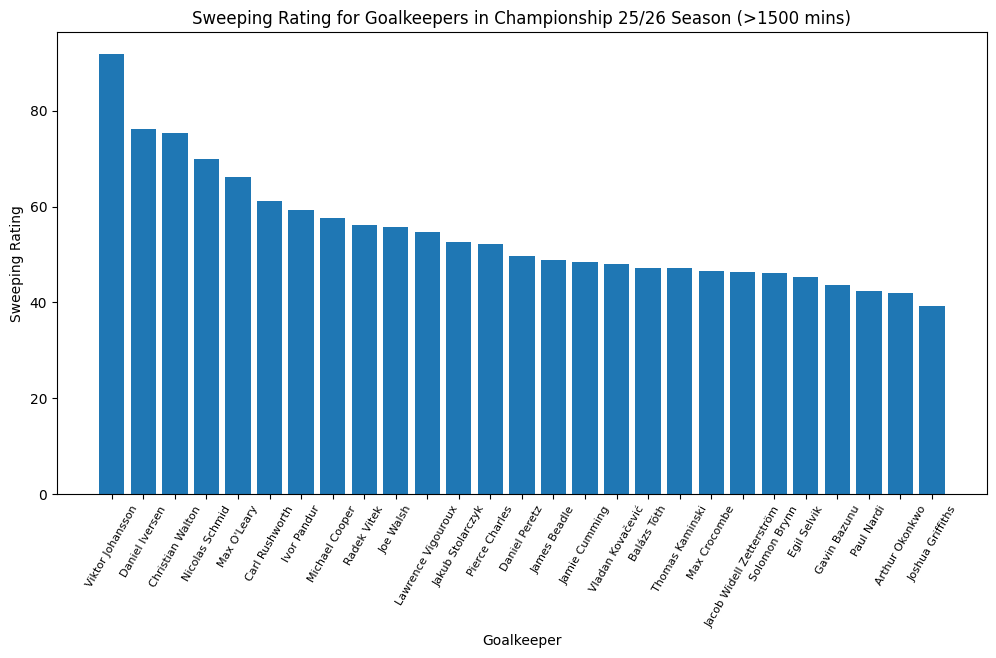

In [145]:
plt.figure(figsize=(12, 6))
plt.bar(sweeping_rating_data['player'], sweeping_rating_data['sweeping_overall_rating'])
plt.xticks(size=8, rotation=60)
plt.xlabel('Goalkeeper')
plt.ylabel('Sweeping Rating')
plt.title('Sweeping Rating for Goalkeepers in Championship 25/26 Season (>1500 mins)')
plt.plot()

## Aerial Data

In [146]:
gk_data1500.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
Index: 27 entries, 3 to 44
Data columns (total 119 columns):
 #    Column                                  Non-Null Count  Dtype  
---   ------                                  --------------  -----  
 0    accurateChippedPasses                   27 non-null     float64
 1    accurateCrosses                         27 non-null     int64  
 2    accurateCrossesPercentage               27 non-null     int64  
 3    accurateFinalThirdPasses                27 non-null     float64
 4    accurateLongBalls                       27 non-null     float64
 5    accurateLongBallsPercentage             27 non-null     float64
 6    accurateOppositionHalfPasses            27 non-null     float64
 7    accurateOwnHalfPasses                   27 non-null     float64
 8    accuratePasses                          27 non-null     float64
 9    accuratePassesPercentage                27 non-null     float64
 10   aerialDuelsWon                          27 non-null    

In [147]:
gk_data1500['highClaimsPercentage'] = (gk_data1500['highClaims'] / (gk_data1500['highClaims'] + gk_data1500['crossesNotClaimed'])) * 100

In [148]:
aerial_cols = [70,49]

In [149]:
aerial_data = gk_data1500.iloc[:,aerial_cols]

In [150]:
scaled_aerial_data = pd.DataFrame(scaler.fit_transform(aerial_data),
                                  columns=aerial_data.columns,
                                  index=aerial_data.index)

In [151]:
scaled_aerial_data.describe()

,punches,highClaims
count,2.700000e+01,2.700000e+01
mean,-3.577385e-16,2.960595e-16
std,1.019049e+00,1.019049e+00
min,-1.354287e+00,-2.841659e+00
25%,-7.393389e-01,-4.116655e-01
50%,-4.082132e-01,3.833323e-02
75%,6.797713e-01,6.683315e-01
max,2.761133e+00,1.838328e+00


In [152]:
aerial_rating_data = np.where(scaled_aerial_data >= 0,
                               100 / (1 + np.exp(-0.9 * scaled_aerial_data)),
                               100 / (1 + np.exp(-0.3 * scaled_aerial_data)))

aerial_rating_data = pd.DataFrame(aerial_rating_data,
                                  columns=aerial_data.columns,
                                  index=aerial_data.index)

In [153]:
aerial_rating_data

,punches,highClaims
3,79.868789,50.862412
4,73.006532,47.589377
6,39.980300,83.949769
7,41.349844,49.612509
8,46.942222,46.916427
9,44.477580,73.233409
12,44.477580,69.941163
13,49.421870,57.883654
14,43.777824,36.772280
16,45.883408,47.589377


In [154]:
aw = 0.5
aerial_weights = pd.Series([aw,aw],
                           index=aerial_data.columns)

aerial_rating_data['aerial_overall_rating'] = aerial_rating_data @ aerial_weights
aerial_rating_data['player'] = gk_data1500['player']

In [155]:
aerial_rating_data = aerial_rating_data.sort_values('aerial_overall_rating', ascending=False)
aerial_rating_data

,punches,highClaims,aerial_overall_rating,player
22,92.308495,50.862412,71.585454,Egil Selvik
3,79.868789,50.862412,65.365601,Daniel Peretz
30,65.799400,64.599903,65.199651,Jakub Stolarczyk
23,75.448436,53.892099,64.670268,Arthur Okonkwo
29,45.179532,80.400181,62.789856,Michael Cooper
6,39.980300,83.949769,61.965035,Lawrence Vigouroux
42,60.861662,60.813959,60.837811,James Beadle
4,73.006532,47.589377,60.297954,Viktor Johansson
19,73.006532,46.244596,59.625564,Vladan Kovačević
9,44.477580,73.233409,58.855494,Pierce Charles


[]

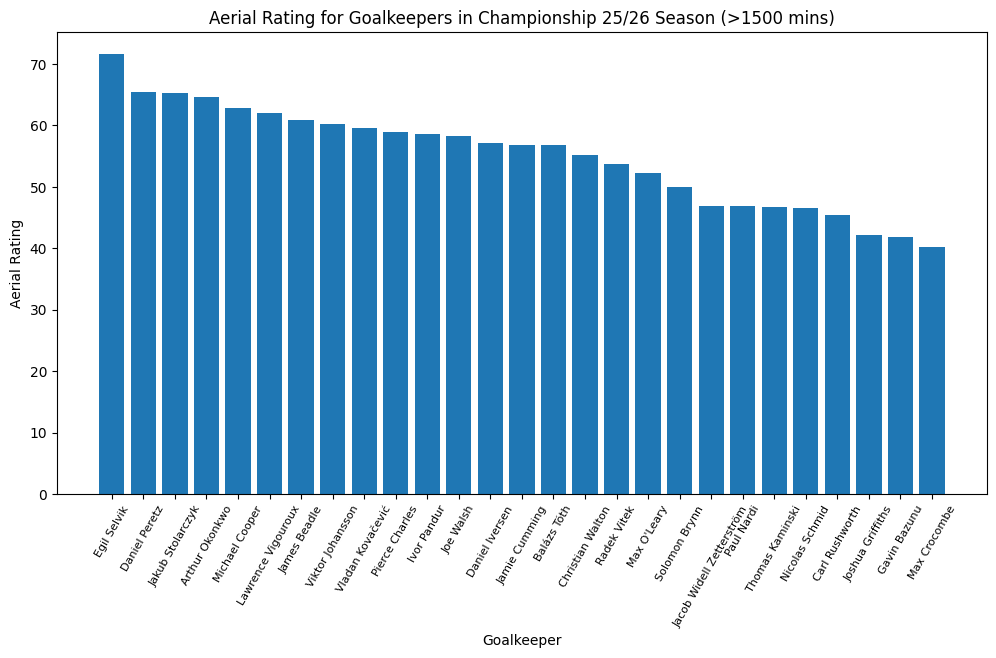

In [156]:
plt.figure(figsize=(12,6))
plt.bar(aerial_rating_data['player'], aerial_rating_data['aerial_overall_rating'])
plt.xticks(size=8, rotation=60)
plt.xlabel('Goalkeeper')
plt.ylabel('Aerial Rating')
plt.title('Aerial Rating for Goalkeepers in Championship 25/26 Season (>1500 mins)')
plt.plot()

## Overall Rating

In [162]:
overall_rating_data = pd.DataFrame([passing_rating_data['passing_overall_rating'],
                  saving_rating_data['saving_overall_rating'],
                  sweeping_rating_data['sweeping_overall_rating'],
                  aerial_rating_data['aerial_overall_rating']],
                  ).T

overall_rating_data.sort_index().head()

,passing_overall_rating,saving_overall_rating,sweeping_overall_rating,aerial_overall_rating
3,55.435137,78.362630,49.625443,65.365601
4,79.545811,69.309438,91.774634,60.297954
6,64.790945,58.039774,54.597872,61.965035
7,61.594922,65.674499,61.260241,45.481176
8,57.421699,67.849694,46.378908,46.929324


In [165]:
ow1 = 0.2
ow2 = 0.45
ow3 = 0.15

overall_weights = pd.Series([ow1,ow2,ow3,ow1],
                            index=overall_rating_data.columns)

overall_rating_data['overall_rating'] = overall_rating_data @ overall_weights

In [166]:
overall_rating_data['player'] = gk_data1500['player']
overall_rating_data = overall_rating_data.sort_values('overall_rating', ascending=False)

overall_rating_data

,passing_overall_rating,saving_overall_rating,sweeping_overall_rating,aerial_overall_rating,overall_rating,player
4,79.545811,69.309438,91.774634,60.297954,72.924195,Viktor Johansson
3,55.435137,78.362630,49.625443,65.365601,66.867147,Daniel Peretz
25,71.628614,66.917758,75.265544,55.241655,66.776877,Christian Walton
12,50.580509,60.723068,76.198651,57.209371,60.313154,Daniel Iversen
7,61.594922,65.674499,61.260241,45.481176,60.157780,Carl Rushworth
6,64.790945,58.039774,54.597872,61.965035,59.658775,Lawrence Vigouroux
20,49.851592,62.516785,59.269629,58.639221,58.721160,Ivor Pandur
22,62.936237,55.470360,45.301697,71.585454,58.661255,Egil Selvik
8,57.421699,67.849694,46.378908,46.929324,58.359403,Jacob Widell Zetterström
19,67.509602,57.101483,48.058270,59.625564,58.331441,Vladan Kovačević


[]

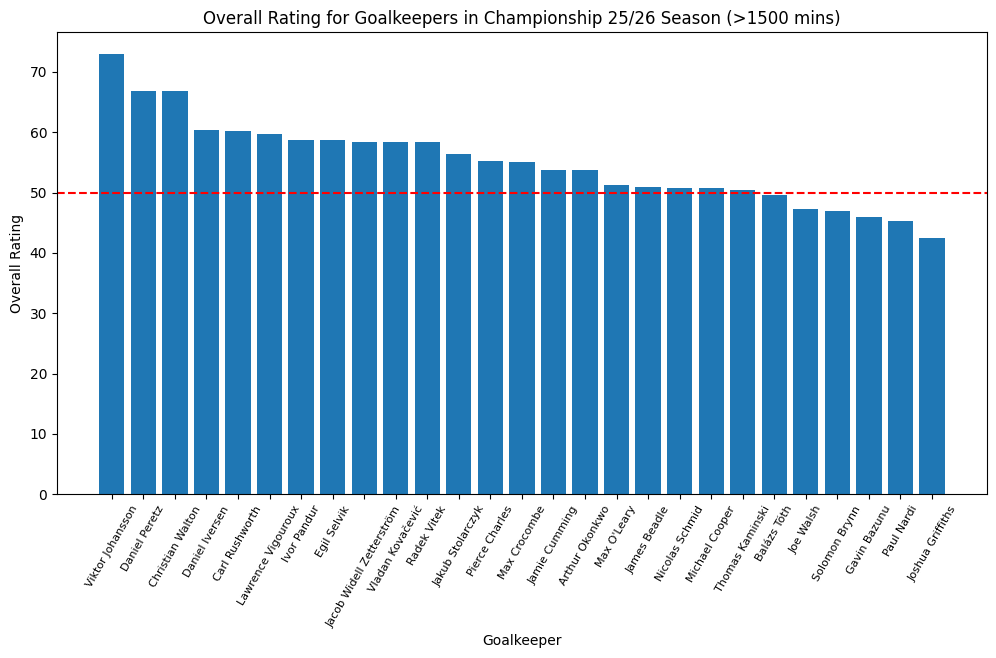

In [171]:
plt.figure(figsize=(12,6))
plt.bar(overall_rating_data['player'],
        overall_rating_data['overall_rating'])
plt.axhline(50, color='red', linestyle='dashed')
plt.xticks(size=8, rotation=60)
plt.xlabel('Goalkeeper')
plt.ylabel('Overall Rating')
plt.title('Overall Rating for Goalkeepers in Championship 25/26 Season (>1500 mins)')
plt.plot()

# Final Notes
## Models
All models used the same values and format. In this case a logarithmic function was used and the exact function can be seen below:
<br>
$$
f(x) =
\begin{cases}
\frac{1}{1 + e^{-0.9x}} & x \ge 0\\
\frac{1}{1 + e^{-0.3x}} & x < 0
\end{cases}
$$
<br>
All weights are based on my own opinion of their importance to the position
## Data
All data was sourced from SofaScore and scraped using ScraperFC
## Future Work
Increase the multiplier for $x$ so that above average players are rated more appropriately